# 07 · IHC Stain Quantification versus Expert Annotations

**C-Stroke dataset · case HB02CV · whole-slide immunohistochemistry**

Every immunohistochemistry (IHC) slide in the C-Stroke dataset is stained for a single protein with DAB, the brown chromogen, and many slides carry expert annotations: polygons that grade the tissue, for example as *sparse*, *moderately dense* or *dense* reactive astrocytes. This notebook asks a quantitative question:

> **How much of the expert annotation can be reproduced from the amount of DAB stain alone?**

The answer is a baseline for any automated method. Where stain intensity already reproduces the annotation, a calibrated threshold is a usable surrogate. Where it does not, the annotation encodes morphology or anatomical context that a simple intensity measure cannot capture.

### What the notebook does
1. Loads the public slide catalogue and summarises annotation coverage by protein and block.
2. Walks through one GFAP slide: its annotations, the cellular appearance of each grade, and colour deconvolution of the DAB signal.
3. Measures DAB across the whole section on a regular tile grid and compares it with the annotation grade (rank correlation, ROC analysis, threshold sweep, spatial error map).
4. Inspects the tiles where stain and annotation disagree.
5. Repeats the comparison on several slides for every annotated protein.

### Data access
All data are read from the public C-Stroke deployment at `https://c-stroke.humanbrain.in`: the slide catalogue (`sets_data.json`), the IIPImage server that streams the whole-slide images, and the annotation API. No credentials, Google Drive files or internal services are required. Downloads are cached under `~/.cache/cstroke`, so re-running a cell does not download the same region twice.

### Requirements and runtime
CPU only; runs on Google Colab, Kaggle or a local Jupyter installation. The first full run takes about 10–15 minutes, most of it spent downloading image regions for the cross-protein comparison in Section 8. Later runs read from the cache.

### How to explore
Every tunable setting is in the **Configuration** cell (Section 1.2): the slide analysed in the walkthrough, the analysis resolution, the tile size, the DAB threshold, the tile inclusion rules and the size of the cross-protein comparison. Each section closes with suggestions for what to change.

### Contents
1. Setup
2. The public slide catalogue
3. The example slide and its annotations
4. Separating the DAB signal
5. Whole-section quantification
6. Agreement between stain and annotation
7. Where stain and annotation disagree
8. Comparison across proteins
9. Summary and limitations

## 1. Setup

### 1.1 Environment

The analysis uses `slide_utils.py`, a small module in the repository root (next to `roi_utils.py`, `annotations_utils.py` and `mri_utils.py`) that wraps the public catalogue, image server and annotation API. When the notebook runs outside the repository, for example on Colab, the module is downloaded from `SLIDE_UTILS_URL`.

In [1]:
import sys
import urllib.request
from pathlib import Path

SLIDE_UTILS_URL = "https://raw.githubusercontent.com/24f2007780/stroke_utils/main/slide_utils_v1.py"

# Use the repository copy when available (notebooks/ or the repository root), otherwise download it.
repo_root = next((p for p in (Path.cwd(), Path.cwd().parent) if (p / "slide_utils_v1.py").exists()), None)
if repo_root is None:
    urllib.request.urlretrieve(SLIDE_UTILS_URL, "slide_utils_v1.py")
    repo_root = Path.cwd()
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

In [2]:
from concurrent.futures import ThreadPoolExecutor

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle
from scipy import ndimage as ndi
from scipy import stats
from sklearn.metrics import roc_auc_score, roc_curve

import slide_utils_v1 as su

su.set_plot_style()
pd.set_option("display.float_format", "{:.3f}".format)
pd.set_option("display.max_colwidth", 60)
print("slide_utils_v1 loaded from", su.__file__)

slide_utils_v1 loaded from /home/antareep/workspace/stroke_notebook/stroke_utils/slide_utils_v1.py


### 1.2 Configuration

| Parameter | Meaning |
|---|---|
| `PROTEIN`, `BIOSAMPLE`, `SECTION` | The IHC slide used in the walkthrough (Sections 3–7). Section 2 shows how to list alternatives. |
| `DOWNSAMPLE` | Fetch resolution relative to the full-resolution scan. The scan is about 0.5 µm per pixel, so `8` gives about 4 µm per pixel. |
| `TILE_UM` | Edge length of the analysis tiles in micrometres. Stain and annotation are compared tile by tile. |
| `DAB_THRESHOLD` | Optical density above which a pixel counts as DAB-positive. |
| `MIN_TISSUE_FRACTION` | Tiles with less tissue than this are ignored (glass, tears, section edge). |
| `MIN_ANNOTATED_FRACTION`, `MAX_UNANNOTATED_FRACTION` | A tile is *annotated* when at least `MIN_ANNOTATED_FRACTION` of it lies inside a polygon and *not annotated* when at most `MAX_UNANNOTATED_FRACTION` does. Tiles in between straddle a polygon boundary and are excluded. |
| `COHORT_PROTEINS`, `SLIDES_PER_PROTEIN` | Proteins and number of randomly drawn slides per protein for the comparison in Section 8. |
| `MIN_ANNOTATED_AREA_MM2`, `MIN_ANNOTATED_TILES` | Slides with less annotated area than this are not drawn for Section 8, and a slide's AUC is reported only when it has at least this many annotated tiles. Some APP and GAP43 slides carry only a few small polygons, too few for a tile-level comparison. |

In [3]:
# Walkthrough slide (Sections 3-7)
PROTEIN = "GFAP"
BIOSAMPLE = 313
SECTION = 1583

# Analysis resolution and tile grid
DOWNSAMPLE = 8              # ~4 um/px
TILE_UM = 256               # tile edge (um)

# DAB positivity
DAB_THRESHOLD = 0.02        # optical density

# Tile inclusion rules
MIN_TISSUE_FRACTION = 0.75
MIN_ANNOTATED_FRACTION = 0.50
MAX_UNANNOTATED_FRACTION = 0.05

# Cross-protein comparison (Section 8)
COHORT_PROTEINS = ["HIF1a", "FIB", "CD68", "GFAP", "CD34", "APP", "GAP43"]
SLIDES_PER_PROTEIN = 3
MIN_ANNOTATED_AREA_MM2 = 10.0
MIN_ANNOTATED_TILES = 25

RANDOM_SEED = 7

### 1.3 Analysis functions

The functions below are used throughout the notebook. `quantify_slide` is the core of the analysis: it streams one IHC slide from the image server, measures DAB on every tile and attaches the annotation grade of each tile.

Per tile it records:

* `tissue_fraction`: share of the tile covered by tissue;
* `dab_mean`: mean DAB optical density over the tissue in the tile;
* `dab_pos_fraction`: share of the tissue whose DAB optical density exceeds `DAB_THRESHOLD`;
* `annotated_fraction` and `grade`: share of the tile inside any annotation polygon, and the dominant annotation grade (0 = not annotated);
* `included`: whether the tile passes the inclusion rules from the configuration.

In [4]:
TILE_PX = int(round(TILE_UM / (su.MPP_LEVEL0 * DOWNSAMPLE)))          # tile edge in fetched pixels
PREVIEW_FACTOR = next(f for f in (8, 4, 2, 1) if TILE_PX % f == 0)     # preview resolution for plots and labels


def dab_features(rgb):
    # Per-pixel measurements for one image chunk; averaged per tile by su.tile_features.
    _, dab = su.stain_separation(rgb)
    tissue = su.tissue_mask(rgb, sigma=2)
    return {"tissue": tissue, "dab_od": dab * tissue, "dab_pos": (dab > DAB_THRESHOLD) & tissue}


def quantify_slide(slide, verbose=True):
    # Tile-level DAB measurements and annotation grades for one catalogue row.
    feats, grid, preview, preview_region = su.tile_features(
        slide.path, dab_features, tile=TILE_PX, downsample=DOWNSAMPLE,
        preview_factor=PREVIEW_FACTOR, verbose=verbose)
    annotations = su.load_annotations(slide.annotation_url)
    grade, annotated_fraction = su.tile_labels(annotations, grid, preview_region,
                                               min_fraction=MIN_ANNOTATED_FRACTION)
    rows, cols = np.indices(grid.shape)
    tissue = feats["tissue"]
    with np.errstate(invalid="ignore", divide="ignore"):
        tiles = pd.DataFrame({
            "row": rows.ravel(),
            "col": cols.ravel(),
            "tissue_fraction": tissue.ravel(),
            "dab_mean": (feats["dab_od"] / tissue).ravel(),
            "dab_pos_fraction": (feats["dab_pos"] / tissue).ravel(),
            "annotated_fraction": annotated_fraction.ravel(),
            "grade": grade.ravel(),
        })
    tiles["included"] = (tiles.tissue_fraction >= MIN_TISSUE_FRACTION) & (
        (tiles.annotated_fraction >= MIN_ANNOTATED_FRACTION)
        | (tiles.annotated_fraction <= MAX_UNANNOTATED_FRACTION))
    return tiles, grid, preview, preview_region


def tile_map(tiles, column, grid, mask=None):
    # Reshape a per-tile column onto the tile grid; NaN where `mask` is False.
    values = tiles[column].to_numpy(dtype=float).reshape(grid.shape)
    if mask is not None:
        values = np.where(np.asarray(mask).reshape(grid.shape), values, np.nan)
    return values


def fetch_field(path, center, size_um, downsample):
    # Square field of `size_um` centred on a level-0 point.
    size = size_um / su.MPP_LEVEL0
    return su.fetch_region(path, center[0] - size / 2, center[1] - size / 2, size, size, downsample=downsample)


def fetch_many(path, origins, size, downsample, workers=8):
    # Fetch several square level-0 regions of edge `size` in parallel; returns a list of RGB arrays.
    def one(xy):
        return su.fetch_region(path, xy[0], xy[1], size, size, downsample=downsample)[0]
    with ThreadPoolExecutor(max_workers=workers) as ex:
        return list(ex.map(one, origins))


def grade_cmap(n_grades):
    colors = [su.GRADE_COLORS[g] for g in range(n_grades)]
    return ListedColormap(colors), BoundaryNorm(np.arange(-0.5, n_grades), n_grades)


print(f"Tiles: {TILE_UM} um = {TILE_PX} px at {su.MPP_LEVEL0 * DOWNSAMPLE:.1f} um/px")

Tiles: 256 um = 64 px at 4.0 um/px


## 2. The public slide catalogue

The catalogue `sets_data.json` organises the dataset into **sets**. A set is anchored on one IHC section and lists its nearest Nissl, H&E and myelin sections from the same block, with their positions along the block. All slides of a set are registered to a common 192,000 × 192,000 pixel canvas, so a coordinate on one slide points at the same anatomy on the others. The companion notebooks depend on this property.

`su.load_slide_catalog()` flattens the catalogue into one row per slide and set. A Nissl, H&E or myelin section is often the nearest neighbour of several IHC sections, so it appears once in each of those sets; drop duplicates on `["biosample", "stain", "section"]` to count physical slides.

In [5]:
catalog = su.load_slide_catalog()
slides = catalog.drop_duplicates(["biosample", "stain", "section"])
print(f"{catalog.set_id.nunique()} sets, {len(slides)} distinct slides, blocks {sorted(catalog.biosample.unique())}")
print("Distinct slides per stain:", slides.groupby("stain").size().rename(su.STAIN_LABELS).to_dict())
catalog.head(8)

505 sets, 1124 distinct slides, blocks [217, 218, 313, 314, 315]
Distinct slides per stain: {'H&E': 234, 'Immunohistochemistry': 505, 'Myelin': 137, 'Nissl': 248}


,set_id,slot,biosample,section,stain,protein,path,annotation_url,annotation_key,z_mm,dist_from_anchor_mm,global_id
0,0,1,314,1463,IHC,CD68,/stroke2d/storageIIT/584/IHCS/B_584_HB2CV[LL1][CD68]-SL_...,https://c-stroke.humanbrain.in/histology_detections/open...,CD68,1.120,0.000,56
1,0,2,314,1465,N,None,/stroke2d/storageIIT/584/NISL/B_584_HB2CV[LL1]-SL_489-ST...,None,None,1.080,-0.040,54
2,0,3,314,1466,HE,HE,/stroke2d/storageIIT/584/HEOS/B_584_HB2CV[LL1]-SL_489-ST...,None,None,1.060,-0.060,53
3,0,4,314,1323,M,None,/stroke2d/storageIIT/584/MYEL/B_584_HB2CV[LL1]-SL_441-ST...,None,None,3.920,2.800,196
4,1,1,314,1445,IHC,HIF1a,/stroke2d/storageIIT/584/IHCS/B_584_HB2CV[LL1][HIF1a]-SL...,https://c-stroke.humanbrain.in/histology_detections/open...,HIF1a,1.480,0.000,74
5,1,2,314,1444,N,None,/stroke2d/storageIIT/584/NISL/B_584_HB2CV[LL1]-SL_482-ST...,None,None,1.500,0.020,75
6,1,3,314,1436,HE,HE,/stroke2d/storageIIT/584/HEOS/B_584_HB2CV[LL1]-SL_479-ST...,None,None,1.660,0.180,83
7,1,4,314,1323,M,None,/stroke2d/storageIIT/584/MYEL/B_584_HB2CV[LL1]-SL_441-ST...,None,None,3.920,2.440,196


### 2.1 Annotation coverage

Not every IHC slide is annotated, and coverage differs between blocks. The left panel counts annotated IHC slides per protein and block. The right panel compares annotated slides with all IHC slides for each protein. H&E slides carry a separate *infarcted region* annotation, which is used in the companion notebook on peri-infarct gradients.

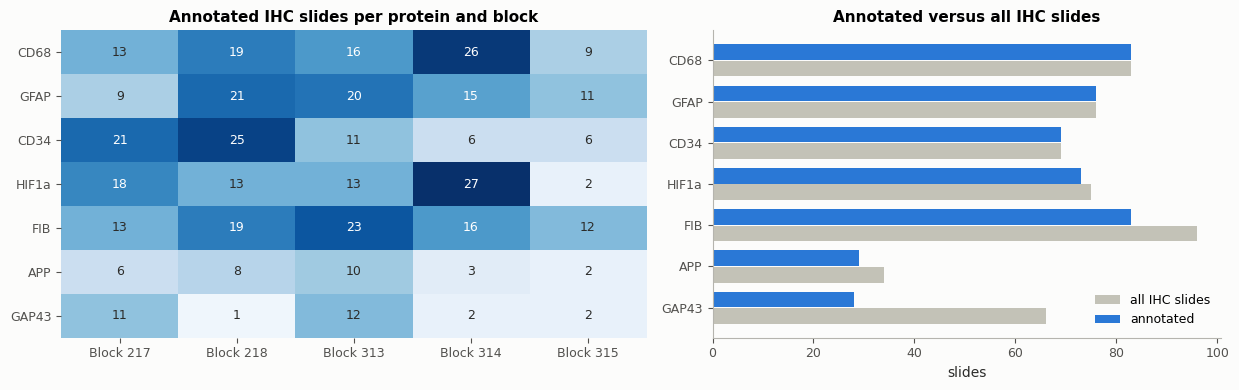

H&E slides with an infarct annotation, per block: {313: 39, 314: 46, 315: 29}


In [6]:
ihc = catalog[catalog.stain == "IHC"]
protein_order = [p for p in su.PROTEIN_INFO if p in set(ihc.loc[ihc.annotation_url.notna(), "protein"])]

coverage = (ihc[ihc.annotation_url.notna()]
            .pivot_table(index="protein", columns="biosample", values="section", aggfunc="count", fill_value=0)
            .reindex(protein_order).fillna(0).astype(int))
totals = pd.DataFrame({
    "all IHC slides": ihc.groupby("protein").size(),
    "annotated": ihc[ihc.annotation_url.notna()].groupby("protein").size(),
}).reindex(protein_order).fillna(0).astype(int)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4), gridspec_kw={"width_ratios": [1.15, 1]})
im = ax1.imshow(coverage.values, cmap="Blues", aspect="auto", vmin=0)
ax1.set_xticks(range(coverage.shape[1]), [f"Block {b}" for b in coverage.columns])
ax1.set_yticks(range(coverage.shape[0]), coverage.index)
for (r, c), v in np.ndenumerate(coverage.values):
    ax1.text(c, r, v, ha="center", va="center", fontsize=9,
             color="white" if v > coverage.values.max() * 0.55 else "#2b2b29")
ax1.set_title("Annotated IHC slides per protein and block")
ax1.spines[:].set_visible(False)

y = np.arange(len(totals))
ax2.barh(y + 0.2, totals["all IHC slides"], height=0.38, color="#c3c2b7", label="all IHC slides")
ax2.barh(y - 0.2, totals["annotated"], height=0.38, color="#2a78d6", label="annotated")
ax2.set_yticks(y, totals.index)
ax2.invert_yaxis()
ax2.set_xlabel("slides")
ax2.set_title("Annotated versus all IHC slides")
ax2.legend(loc="lower right")
plt.tight_layout()
plt.show()

he = slides[(slides.stain == "HE") & slides.annotation_url.notna()]
print("H&E slides with an infarct annotation, per block:", he.groupby("biosample").size().to_dict())

### 2.2 Anatomy of a set

The slides of the set that contains the walkthrough slide (up to four; a few sets lack one of the stains), cropped to the same window of the shared canvas. The distance printed above each panel is its offset along the cutting axis from the IHC section. Adjacent 20 µm sections are not identical, but at this scale the anatomy, and the lesion, line up across stains.

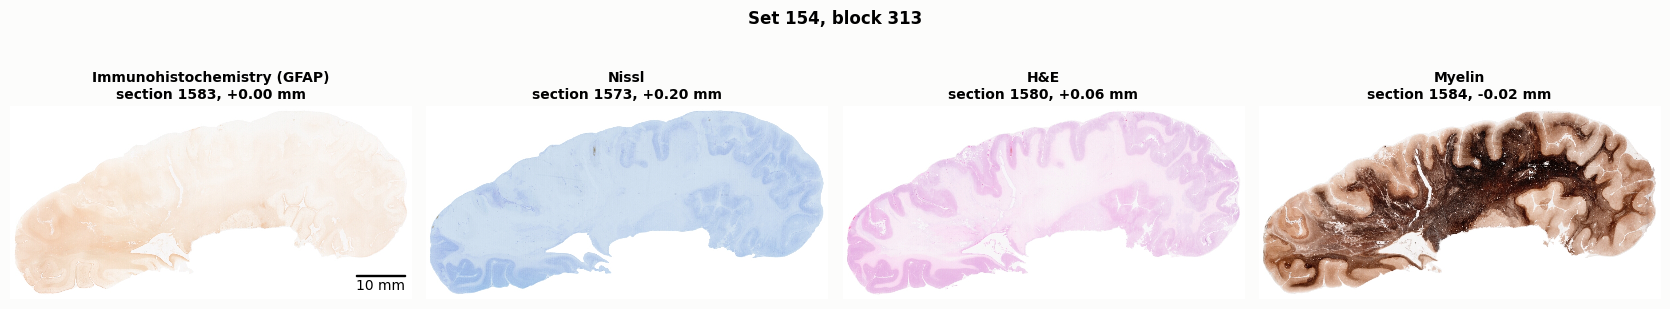

In [7]:
slide = catalog.query("stain == 'IHC' and protein == @PROTEIN and biosample == @BIOSAMPLE and section == @SECTION")
if slide.empty:
    raise ValueError(f"No IHC slide for {PROTEIN} in block {BIOSAMPLE}, section {SECTION}. "
                     "List candidates with su.find_slides(catalog, protein=PROTEIN, annotated=True).")
slide = slide.iloc[0]
members = su.slide_set(catalog, slide.set_id)

bbox = su.tissue_bbox(slide.path)
fig, axes = plt.subplots(1, len(members), figsize=(4.2 * len(members), 3.4))
for ax, (_, m) in zip(np.atleast_1d(axes), members.iterrows()):
    img, reg = su.fetch_region(m.path, *bbox, downsample=max(bbox[2], bbox[3]) / 1200)
    ax.imshow(img)
    name = su.STAIN_LABELS[m.stain] + (f" ({m.protein})" if m.stain == "IHC" else "")
    ax.set_title(f"{name}\nsection {m.section}, {m.dist_from_anchor_mm:+.2f} mm", fontsize=10)
    ax.axis("off")
su.scale_bar(np.atleast_1d(axes)[0], reg, 10)
plt.suptitle(f"Set {slide.set_id}, block {slide.biosample}", y=1.02, fontweight="bold")
plt.tight_layout()
plt.show()

*To explore:* `su.find_slides(catalog, protein="CD68", annotated=True)` lists every annotated CD68 slide. Set `PROTEIN`, `BIOSAMPLE` and `SECTION` in the configuration to any row and re-run the notebook from Section 2.2.

## 3. The example slide and its annotations

Annotation polygons are downloaded from the public API and converted to full-resolution slide pixels. Each polygon carries a class name. `slide_utils` orders the classes of each protein by severity and stores the position as an integer **grade** (1 = mildest class, 0 = not annotated).

In [8]:
annotations = su.load_annotations(slide.annotation_url)
classes = su.annotation_classes(PROTEIN)
n_grades = len(classes)

print(f"{PROTEIN} ({su.PROTEIN_INFO[PROTEIN]['marker']}), block {slide.biosample}, section {slide.section}")
print(f"{len(annotations)} annotation polygons\n")

um2_per_px = su.MPP_LEVEL0 ** 2
annotation_summary = (
    pd.DataFrame({"grade": [a["grade"] for a in annotations],
                  "class": [a["label"] for a in annotations],
                  "area_mm2": [a["geometry"].area * um2_per_px / 1e6 for a in annotations]})
    .groupby(["grade", "class"]).area_mm2
    .agg(polygons="count", total_area_mm2="sum", median_polygon_mm2="median")
    .reset_index())
annotation_summary

GFAP (Reactive astrocytes), block 313, section 1583
163 annotation polygons



,grade,class,polygons,total_area_mm2,median_polygon_mm2
0,1,sparse astrocytes,93,228.810,0.355
1,2,moderately dense astrocytes,51,92.248,0.281
2,3,dense astrocytes,19,43.111,0.185


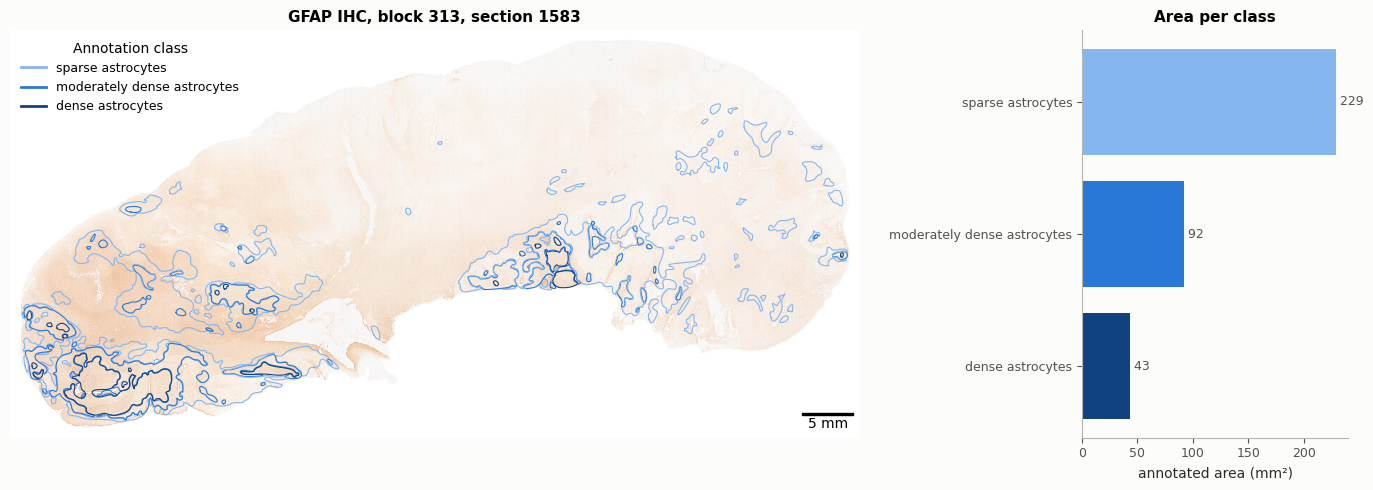

In [9]:
overview, overview_region = su.fetch_region(slide.path, *bbox, downsample=max(bbox[2], bbox[3]) / 2000)

fig, (ax, axb) = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [3.3, 1]})
ax.imshow(overview)
su.draw_annotation_outlines(ax, annotations, overview_region, linewidth=0.8)
su.scale_bar(ax, overview_region, 5)
ax.legend(handles=[Line2D([], [], color=su.GRADE_COLORS[g], lw=2, label=classes[g]) for g in range(1, n_grades)],
          loc="upper left", title="Annotation class")
ax.set_title(f"{PROTEIN} IHC, block {slide.biosample}, section {slide.section}")
ax.axis("off")

axb.barh(annotation_summary["class"], annotation_summary.total_area_mm2,
         color=[su.GRADE_COLORS[g] for g in annotation_summary.grade])
for i, v in enumerate(annotation_summary.total_area_mm2):
    axb.text(v, i, f" {v:.0f}", va="center", fontsize=9, color="#52514e")
axb.invert_yaxis()
axb.set_xlabel("annotated area (mm²)")
axb.set_title("Area per class")
plt.tight_layout()
plt.show()

### 3.1 What the grades look like

The overview shows where the annotations are, but the grades are assigned at cellular resolution. The figure below zooms from a 4 mm field to a 250 µm field at full resolution in two places:

* **top row**: deep inside the most severe annotation class;
* **bottom row**: tissue as far as possible from any annotation.

Each field is centred on the point that is farthest from both the class boundary and the tissue edge, so the comparison is not biased by borders.

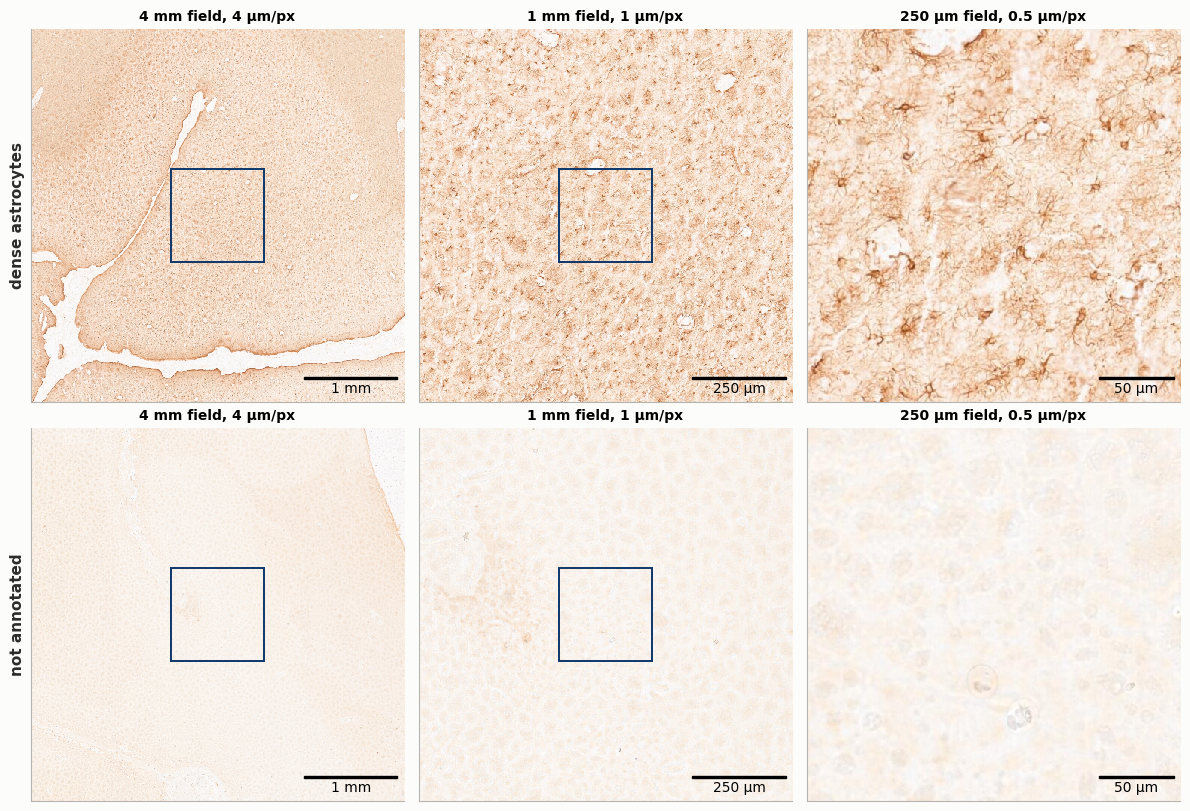

In [10]:
grade_raster = su.rasterize_annotations(annotations, overview_region)
tissue_overview = su.tissue_mask(overview)
depth_in_tissue = ndi.distance_transform_edt(tissue_overview)

top_grade = int(grade_raster.max())
score_dense = np.minimum(ndi.distance_transform_edt(grade_raster == top_grade), depth_in_tissue)
score_clear = np.minimum(ndi.distance_transform_edt(grade_raster == 0), depth_in_tissue)
locations = {
    classes[top_grade]: overview_region.to_level0(*np.unravel_index(score_dense.argmax(), score_dense.shape)[::-1]),
    "not annotated": overview_region.to_level0(*np.unravel_index(score_clear.argmax(), score_clear.shape)[::-1]),
}

FIELDS = [(4000, DOWNSAMPLE, 1.0), (1000, 2, 0.25), (250, 1, 0.05)]   # (field um, downsample, scale bar mm)
fig, axes = plt.subplots(2, 3, figsize=(12, 8.2))
for r, (name, center) in enumerate(locations.items()):
    for c, (size_um, ds, bar_mm) in enumerate(FIELDS):
        img, reg = fetch_field(slide.path, center, size_um, ds)
        ax = axes[r, c]
        ax.imshow(img)
        if c + 1 < len(FIELDS):                          # outline of the next, smaller field
            nxt = FIELDS[c + 1][0] / su.MPP_LEVEL0 / reg.downsample
            mid = img.shape[0] / 2
            ax.add_patch(Rectangle((mid - nxt / 2, mid - nxt / 2), nxt, nxt, fill=False, ec="#0d366b", lw=1.4))
        su.scale_bar(ax, reg, bar_mm)
        ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(f"{size_um / 1000:g} mm field, {reg.mpp:g} µm/px" if size_um >= 1000
                     else f"{size_um} µm field, {reg.mpp:g} µm/px", fontsize=10)
    axes[r, 0].set_ylabel(name, fontsize=11, fontweight="bold")
plt.tight_layout()
plt.show()

At full resolution the difference is unambiguous: the densely annotated tissue is packed with DAB-positive cells and their processes, while the unannotated field shows only faint, diffuse background staining. Section 4 measures this difference.

## 4. Separating the DAB signal

### 4.1 Colour deconvolution

Bright-field stains absorb light. By the Beer–Lambert law, the **optical density** of a pixel, $OD_c = -\log_{10}(I_c / I_0)$ for each colour channel $c$, is a linear sum of the stains present weighted by their concentrations. Colour deconvolution (Ruifrok & Johnston, 2001) inverts this mixture using a reference absorption vector for each stain, so every pixel gets a separate density for haematoxylin and for DAB. `su.stain_separation` uses the standard haematoxylin–DAB vectors from scikit-image.

The slides in this dataset carry **no haematoxylin counterstain**, which the haematoxylin channel below confirms: almost all of the optical density is attributed to DAB. That makes the DAB channel a direct measure of how much chromogen was deposited.

The figure shows two 2 mm fields at the analysis resolution: the original image, the DAB optical density, and the pixels above `DAB_THRESHOLD`.

         dense astrocytes: mean OD in tissue  haematoxylin 0.0002   DAB 0.0267   DAB-positive fraction 0.713
            not annotated: mean OD in tissue  haematoxylin 0.0002   DAB 0.0086   DAB-positive fraction 0.001


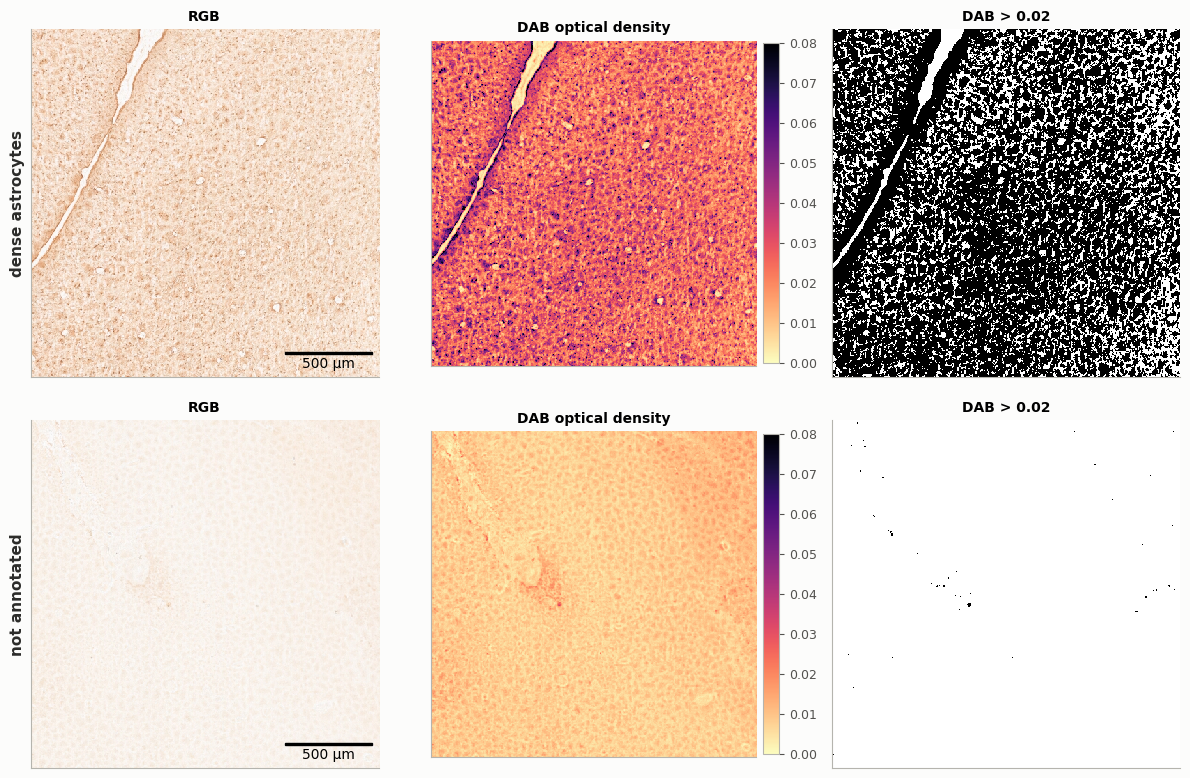

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for r, (name, center) in enumerate(locations.items()):
    img, reg = fetch_field(slide.path, center, 2000, DOWNSAMPLE)
    hema, dab = su.stain_separation(img)
    tissue = su.tissue_mask(img)
    print(f"{name:>25}: mean OD in tissue  haematoxylin {hema[tissue].mean():.4f}   DAB {dab[tissue].mean():.4f}   "
          f"DAB-positive fraction {(dab[tissue] > DAB_THRESHOLD).mean():.3f}")
    panels = [(img, None, "RGB"),
              (dab, "magma_r", "DAB optical density"),
              ((dab > DAB_THRESHOLD) & tissue, "Greys", f"DAB > {DAB_THRESHOLD}")]
    for c, (arr, cmap, title) in enumerate(panels):
        ax = axes[r, c]
        if cmap == "magma_r":
            h = ax.imshow(arr, cmap=cmap, vmin=0, vmax=0.08)
            plt.colorbar(h, ax=ax, fraction=0.046, pad=0.02)
        else:
            ax.imshow(arr, cmap=cmap)
        ax.set_title(title, fontsize=10)
        ax.set_xticks([]); ax.set_yticks([])
    su.scale_bar(axes[r, 0], reg, 0.5)
    axes[r, 0].set_ylabel(name, fontsize=11, fontweight="bold")
plt.tight_layout()
plt.show()

### 4.2 DAB distributions by annotation grade

A single pair of fields is anecdotal. Below, `PATCHES_PER_GRADE` patches of one tile (`TILE_UM`) each are sampled at random from the interior of every grade, including unannotated tissue, and the DAB optical density of all their tissue pixels is pooled. If stain intensity tracks the annotation, the distributions should shift to the right as the grade increases. The dashed line marks `DAB_THRESHOLD`.

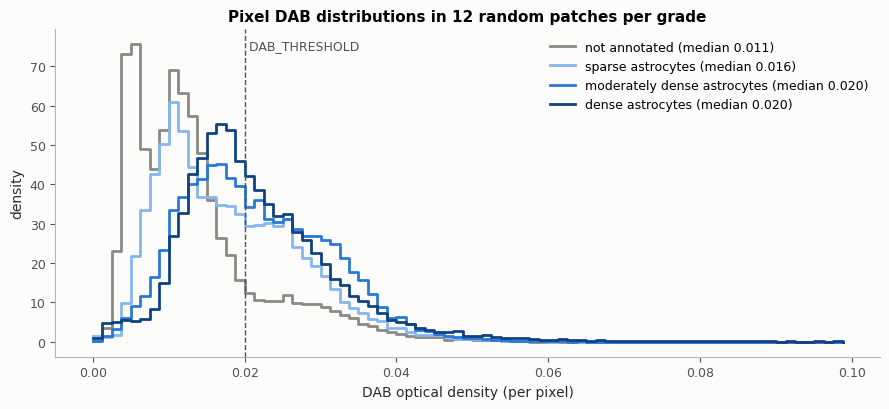

In [12]:
PATCHES_PER_GRADE = 12
rng = np.random.default_rng(RANDOM_SEED)

tile_l0 = TILE_UM / su.MPP_LEVEL0                                     # tile edge in level-0 pixels
margin = int(np.ceil(tile_l0 / 2 / overview_region.downsample)) + 1   # keep patches clear of class boundaries
patch_origins = {}
for g in range(n_grades):
    interior = ndi.binary_erosion(grade_raster == g, iterations=margin) & (depth_in_tissue > margin)
    candidates = np.argwhere(interior)
    if len(candidates) == 0:
        continue
    pick = candidates[rng.choice(len(candidates), min(PATCHES_PER_GRADE, len(candidates)), replace=False)]
    x, y = overview_region.to_level0(pick[:, 1], pick[:, 0])
    patch_origins[g] = list(zip(x - tile_l0 / 2, y - tile_l0 / 2))

patches_analysis = {g: fetch_many(slide.path, o, tile_l0, DOWNSAMPLE) for g, o in patch_origins.items()}
patches_fullres = {g: fetch_many(slide.path, o[:6], tile_l0, 1) for g, o in patch_origins.items()}

fig, ax = plt.subplots(figsize=(9, 4.2))
bins = np.linspace(0, 0.1, 81)
for g, imgs in patches_analysis.items():
    values = np.concatenate([su.stain_separation(im)[1][su.tissue_mask(im)] for im in imgs])
    hist, edges = np.histogram(values, bins=bins, density=True)
    color = su.GRADE_COLORS[g] if g else "#8a8984"
    ax.step(edges[:-1], hist, where="post", lw=2, color=color,
            label=f"{classes[g]} (median {np.median(values):.3f})")
ax.axvline(DAB_THRESHOLD, ls="--", lw=1, color="#52514e")
ax.text(DAB_THRESHOLD, ax.get_ylim()[1] * 0.97, " DAB_THRESHOLD", va="top", fontsize=9, color="#52514e")
ax.set_xlabel("DAB optical density (per pixel)")
ax.set_ylabel("density")
ax.set_title(f"Pixel DAB distributions in {PATCHES_PER_GRADE} random patches per grade")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

The same patches at full resolution (0.5 µm/px), six per grade. The density classes reflect how many cells are stained and how hypertrophic they are, not only how dark the chromogen is.

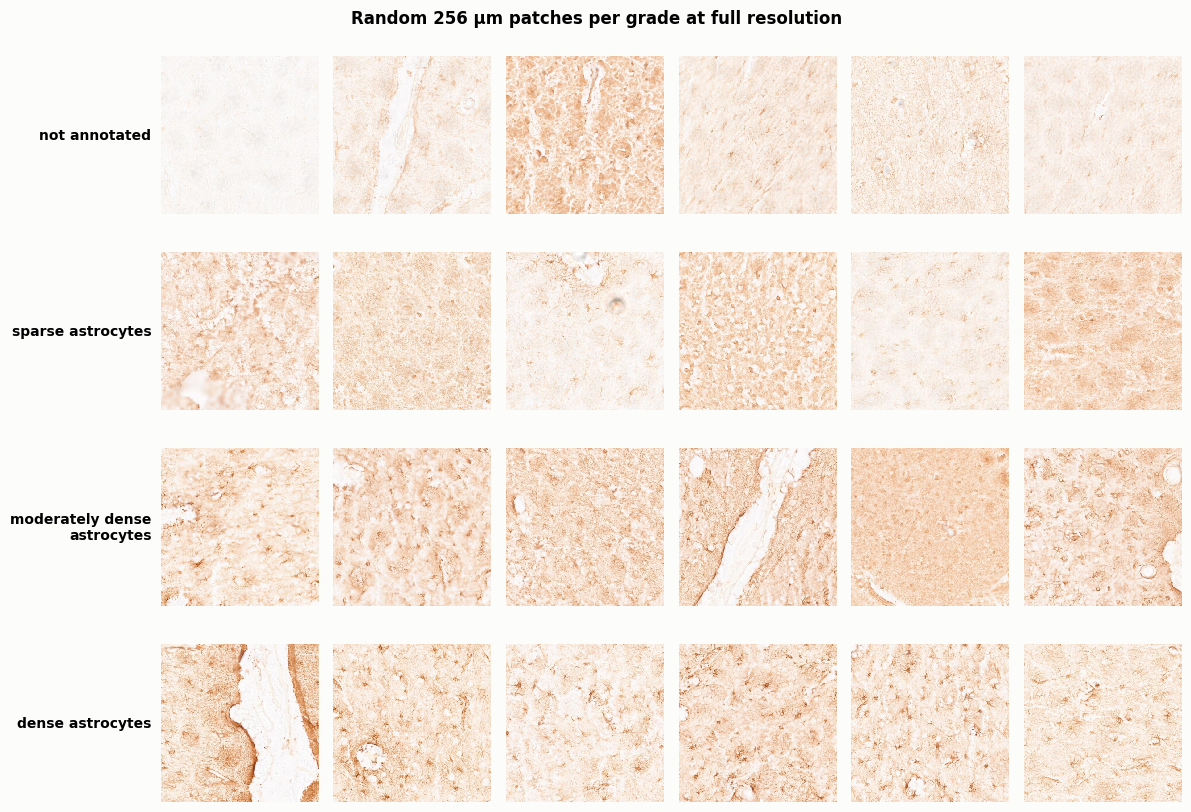

In [13]:
grades_shown = sorted(patches_fullres)
fig, axes = plt.subplots(len(grades_shown), 6, figsize=(12, 2.1 * len(grades_shown)))
for r, g in enumerate(grades_shown):
    for c in range(6):
        ax = axes[r, c]
        ax.axis("off")
        if c < len(patches_fullres[g]):
            ax.imshow(patches_fullres[g][c])
    axes[r, 0].text(-0.06, 0.5, classes[g], transform=axes[r, 0].transAxes, ha="right", va="center",
                    fontsize=10, fontweight="bold", wrap=True)
plt.suptitle(f"Random {TILE_UM} µm patches per grade at full resolution", fontweight="bold")
plt.tight_layout()
plt.show()

*To explore:* raise or lower `DAB_THRESHOLD` and compare where it sits relative to the per-grade distributions. A threshold in the tail of the unannotated distribution separates annotated from unannotated tissue. Separating the annotated grades from each other depends on how much those distributions overlap.

## 5. Whole-section quantification

`quantify_slide` streams the entire section at the analysis resolution in parallel chunks. Only one chunk per worker is held in memory, so a full hemisphere section of roughly 80 × 40 mm can be processed on a free Colab instance. Each tile is then labelled with the annotation grade that covers most of it.

**Tile inclusion.** Tiles that are mostly glass, and tiles that straddle a polygon boundary, are excluded, so every remaining tile is either clearly inside or clearly outside the annotations. Keep in mind that *not annotated* is not the same as *confirmed negative*: an annotator may have left mild or uncertain regions unmarked. Section 7 returns to this point.

In [14]:
tiles, grid, preview, preview_region = quantify_slide(slide)
included = tiles[tiles.included]

counts = (included.grade.value_counts().sort_index()
          .rename(index=dict(enumerate(classes))).rename("tiles").to_frame())
counts["share"] = counts.tiles / counts.tiles.sum()
print(f"{len(tiles)} tiles in the grid, {int((tiles.tissue_fraction >= MIN_TISSUE_FRACTION).sum())} with tissue, "
      f"{len(included)} included")
counts

155 x 325 tiles of 256 um at 4.0 um/px (28 requests, 10.0 s)
50375 tiles in the grid, 29312 with tissue, 28184 included


,tiles,share
grade,,
not annotated,22317,0.792
sparse astrocytes,3654,0.130
moderately dense astrocytes,1515,0.054
dense astrocytes,698,0.025


The three maps below cover the same area. Left: the slide. Centre: the DAB-positive fraction of every tile with tissue. Right: the annotation grade assigned to each tile.

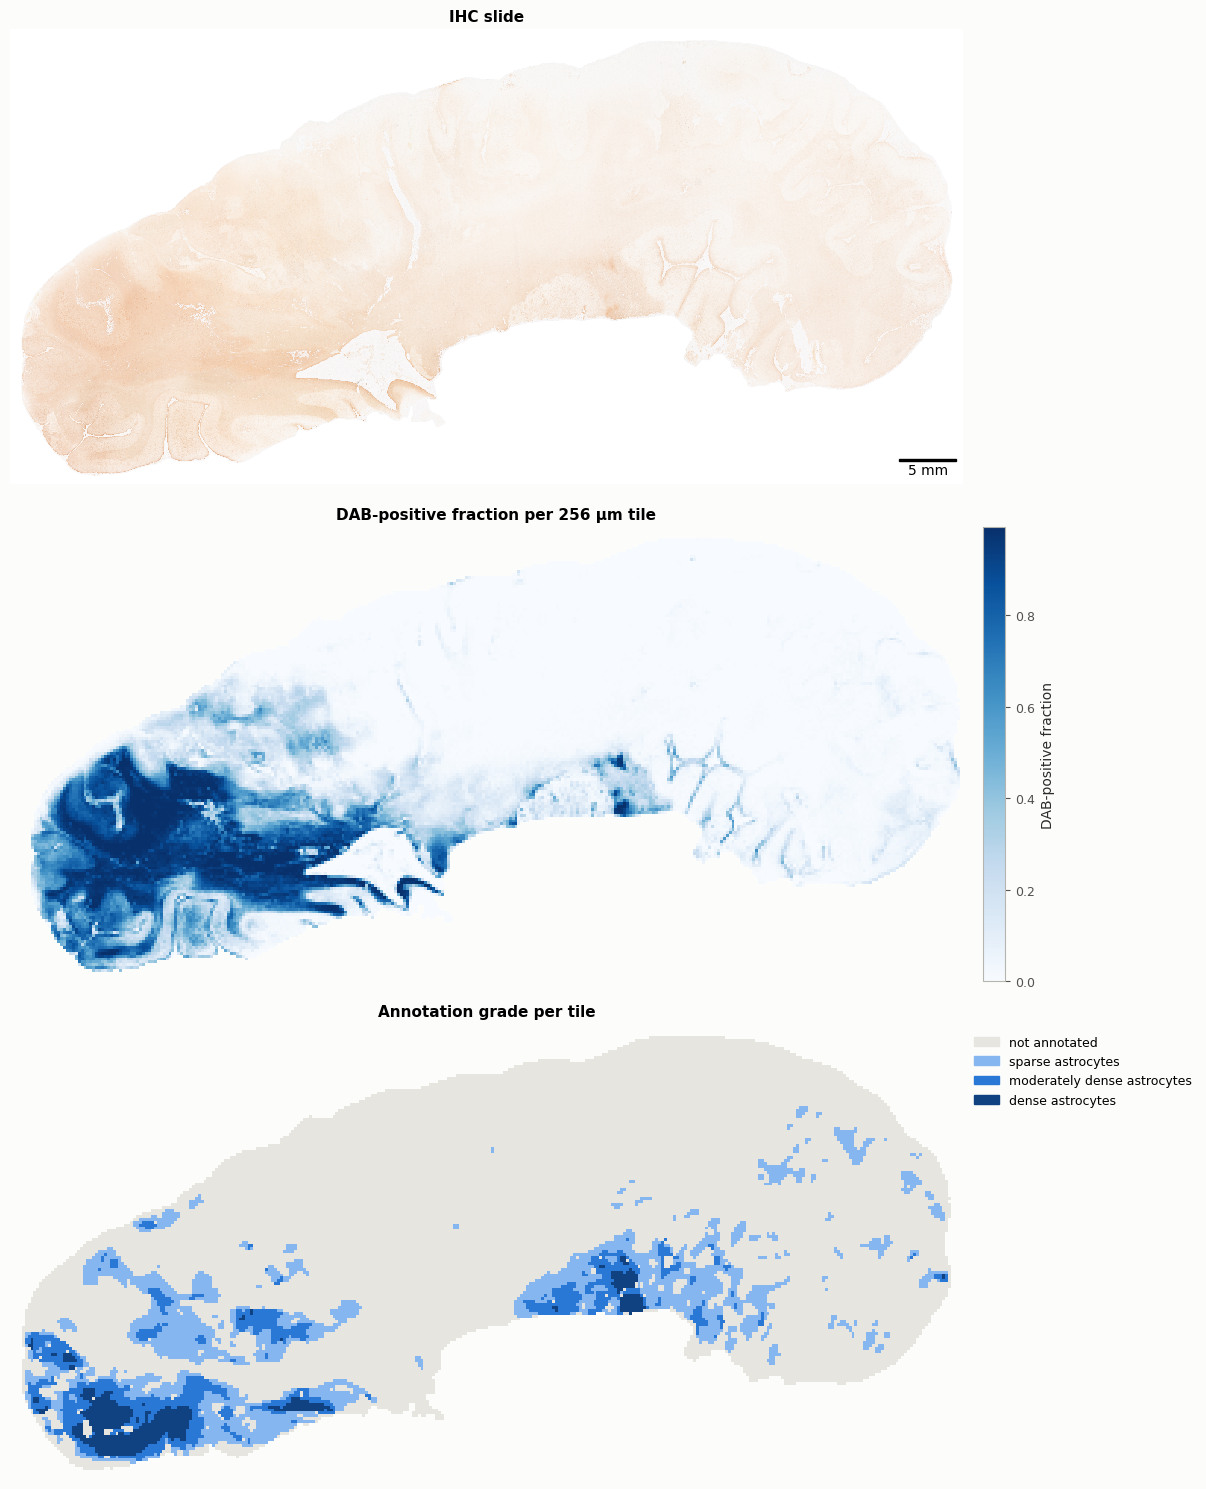

In [15]:
tissue_tiles = (tiles.tissue_fraction >= MIN_TISSUE_FRACTION).to_numpy()
pos_map = tile_map(tiles, "dab_pos_fraction", grid, tissue_tiles)
grade_map = tile_map(tiles, "grade", grid, tissue_tiles)
cmap_g, norm_g = grade_cmap(n_grades)

fig, axes = plt.subplots(3, 1, figsize=(12, 15))
axes[0].imshow(preview)
axes[0].set_title("IHC slide")
h = axes[1].imshow(pos_map, cmap="Blues", vmin=0, vmax=np.nanpercentile(pos_map, 99))
plt.colorbar(h, ax=axes[1], fraction=0.025, pad=0.01, label="DAB-positive fraction")
axes[1].set_title(f"DAB-positive fraction per {TILE_UM} µm tile")
axes[2].imshow(grade_map, cmap=cmap_g, norm=norm_g)
axes[2].legend(handles=[Patch(color=su.GRADE_COLORS[g], label=classes[g]) for g in range(n_grades)],
               loc="upper left", bbox_to_anchor=(1.0, 1.0))
axes[2].set_title("Annotation grade per tile")
for ax in axes:
    ax.axis("off")
su.scale_bar(axes[0], preview_region, 5)
plt.tight_layout()
plt.show()

## 6. Agreement between stain and annotation

Three complementary views of the same question:

1. **Rank correlation.** Does the DAB measure increase with the annotation grade? Spearman's ρ is used because the grade is ordinal.
2. **Discrimination.** How well does the DAB measure separate annotated from unannotated tiles, and the higher grades from the lowest? The area under the ROC curve (AUC) is threshold-free: 0.5 is chance and 1.0 is perfect separation.
3. **A working threshold.** If a tile is called positive whenever its DAB-positive fraction exceeds a cut-off, how do precision, recall and Dice overlap with the annotation change with that cut-off, and where does the error fall on the section?

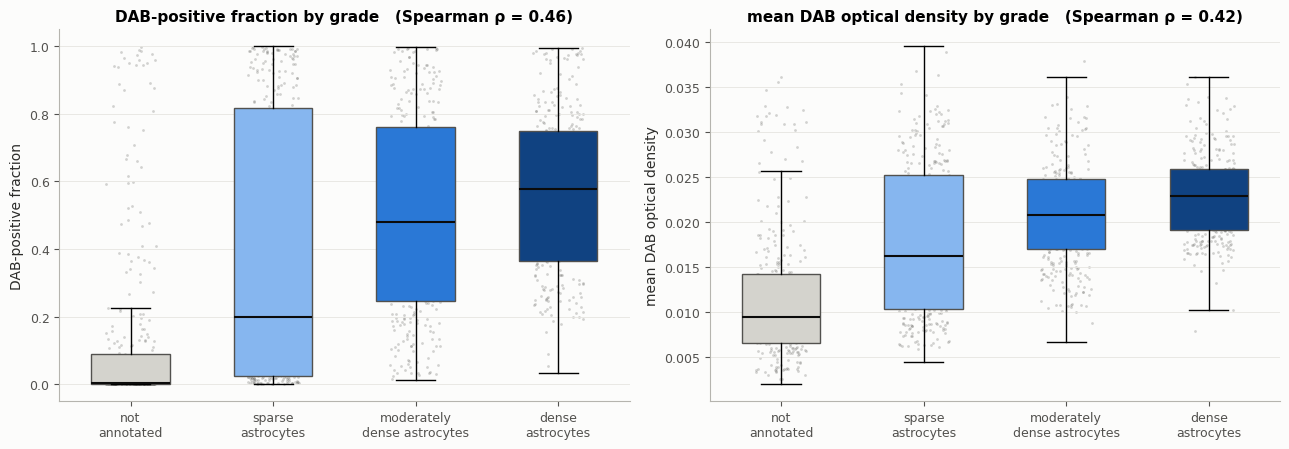

,median DAB-positive fraction,median DAB OD
grade,,
not annotated,0.005,0.009
sparse astrocytes,0.200,0.016
moderately dense astrocytes,0.481,0.021
dense astrocytes,0.578,0.023


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
present = sorted(included.grade.unique())
for ax, column, label in [(axes[0], "dab_pos_fraction", "DAB-positive fraction"),
                          (axes[1], "dab_mean", "mean DAB optical density")]:
    data = [included.loc[included.grade == g, column].to_numpy() for g in present]
    bp = ax.boxplot(data, positions=range(len(present)), widths=0.55, showfliers=False, patch_artist=True,
                    medianprops={"color": "#0b0b0b", "lw": 1.5})
    for patch, g in zip(bp["boxes"], present):
        patch.set_facecolor(su.GRADE_COLORS[g] if g else "#d4d3cd")
        patch.set_edgecolor("#52514e")
    for i, (g, d) in enumerate(zip(present, data)):
        sample = rng.choice(d, min(300, len(d)), replace=False)
        ax.scatter(i + rng.uniform(-0.18, 0.18, len(sample)), sample, s=4, color="#52514e", alpha=0.25, lw=0)
    rho, p = stats.spearmanr(included.grade, included[column])
    ax.set_xticks(range(len(present)), [classes[g].replace(" ", "\n", 1) for g in present])
    ax.set_ylabel(label)
    ax.set_title(f"{label} by grade   (Spearman ρ = {rho:.2f})")
    ax.grid(axis="y")
plt.tight_layout()
plt.show()

summary_by_grade = (included.groupby("grade")[["dab_pos_fraction", "dab_mean"]].median()
                    .rename(index=dict(enumerate(classes))))
summary_by_grade.columns = ["median DAB-positive fraction", "median DAB OD"]
summary_by_grade

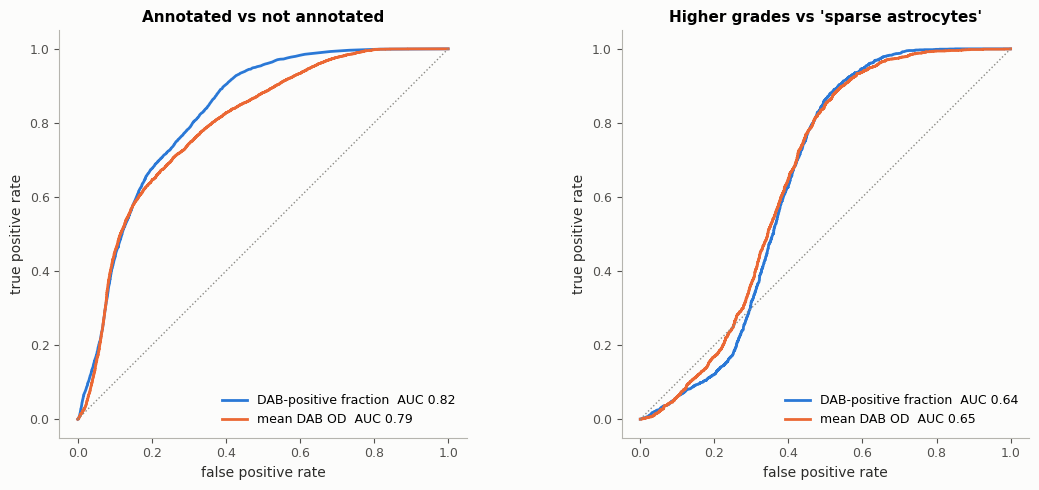

In [17]:
def roc_panel(ax, y_true, scores, title):
    for column, label, color in [("dab_pos_fraction", "DAB-positive fraction", "#2a78d6"),
                                 ("dab_mean", "mean DAB OD", "#eb6834")]:
        fpr, tpr, _ = roc_curve(y_true, scores[column])
        ax.plot(fpr, tpr, lw=2, color=color, label=f"{label}  AUC {roc_auc_score(y_true, scores[column]):.2f}")
    ax.plot([0, 1], [0, 1], ls=":", color="#8a8984", lw=1)
    ax.set_xlabel("false positive rate")
    ax.set_ylabel("true positive rate")
    ax.set_title(title)
    ax.legend(loc="lower right")
    ax.set_aspect("equal")


annotated = included[included.grade > 0]
fig, axes = plt.subplots(1, 2, figsize=(11.5, 5))
roc_panel(axes[0], included.grade > 0, included, "Annotated vs not annotated")
if annotated.grade.nunique() > 1:
    roc_panel(axes[1], annotated.grade > 1, annotated, f"Higher grades vs '{classes[1]}'")
else:
    axes[1].axis("off")
plt.tight_layout()
plt.show()

### 6.1 Choosing a working threshold

A practical surrogate for the annotation calls a tile positive when its DAB-positive fraction exceeds a cut-off τ. The sweep below reports, for every τ, the **precision** (share of predicted tiles that are annotated), the **recall** (share of annotated tiles that are predicted) and their harmonic mean, the **Dice** coefficient. The cut-off with the highest Dice is marked and used for the error map.

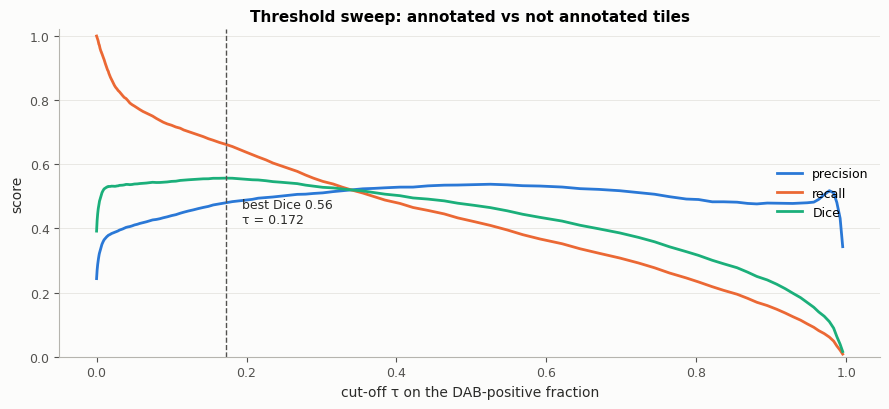

At τ = 0.172: precision 0.48, recall 0.66, Dice 0.56


In [18]:
truth = (included.grade > 0).to_numpy()
score = included.dab_pos_fraction.to_numpy()
taus = np.unique(np.quantile(score, np.linspace(0.01, 0.995, 200)))
tp = np.array([(truth & (score > t)).sum() for t in taus])
fp = np.array([(~truth & (score > t)).sum() for t in taus])
fn = np.array([(truth & ~(score > t)).sum() for t in taus])
precision = tp / np.maximum(tp + fp, 1)
recall = tp / np.maximum(tp + fn, 1)
dice = 2 * tp / np.maximum(2 * tp + fp + fn, 1)
best = int(dice.argmax())
TAU = float(taus[best])

fig, ax = plt.subplots(figsize=(9, 4.2))
for values, label, color in [(precision, "precision", "#2a78d6"), (recall, "recall", "#eb6834"),
                             (dice, "Dice", "#1baf7a")]:
    ax.plot(taus, values, lw=2, color=color, label=label)
ax.axvline(TAU, ls="--", lw=1, color="#52514e")
ax.annotate(f"best Dice {dice[best]:.2f}\nτ = {TAU:.3f}", (TAU, dice[best]), xytext=(12, -32),
            textcoords="offset points", fontsize=9, color="#2b2b29")
ax.set_xlabel("cut-off τ on the DAB-positive fraction")
ax.set_ylabel("score")
ax.set_ylim(0, 1.02)
ax.set_title("Threshold sweep: annotated vs not annotated tiles")
ax.legend(loc="center right")
ax.grid(axis="y")
plt.tight_layout()
plt.show()
print(f"At τ = {TAU:.3f}: precision {precision[best]:.2f}, recall {recall[best]:.2f}, Dice {dice[best]:.2f}")

### 6.2 Where the threshold agrees and disagrees

Each included tile is coloured by the outcome at the best cut-off τ:

* **agree, positive**: annotated, and above τ;
* **stain only**: above τ, but not annotated;
* **annotation only**: annotated, but below τ;
* **agree, negative**: neither.

Spatially clustered errors are more informative than scattered ones: a cluster of *stain only* tiles points to a region the annotator did not mark, or to a staining artefact. A cluster of *annotation only* tiles points to a class the annotator recognised from morphology rather than stain density.

When the set contains an annotated H&E section, its **infarct outline** is drawn on top. Because all slides of a set share one coordinate frame, this shows whether the disagreements fall inside or outside the infarct.

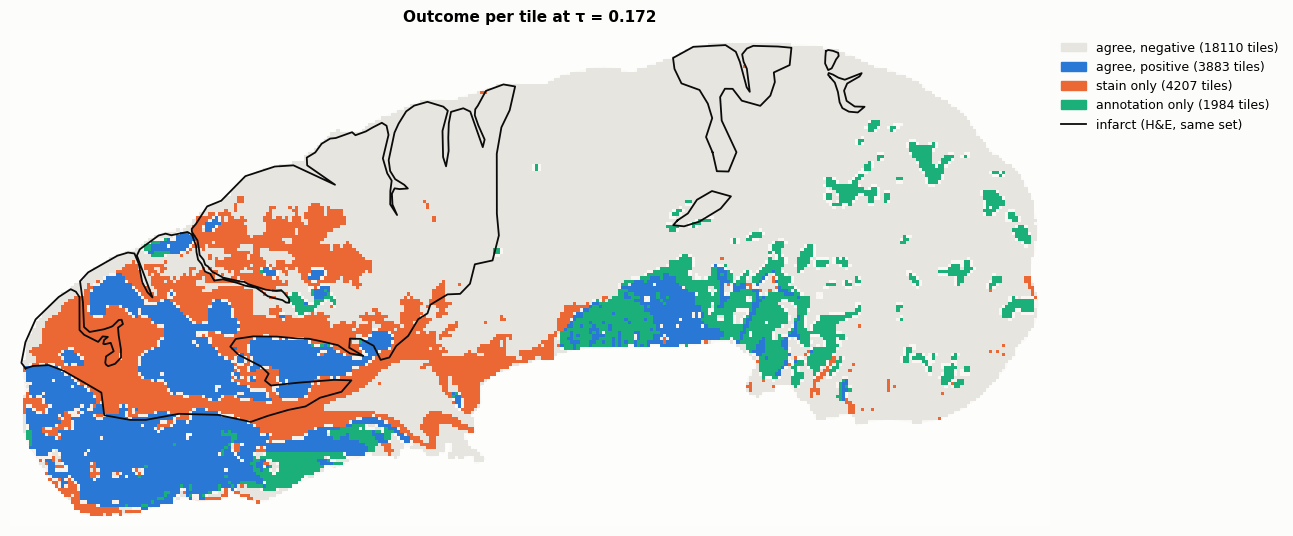

In [19]:
OUTCOMES = {1: ("agree, negative", "#e6e5e0"), 2: ("agree, positive", "#2a78d6"),
            3: ("stain only", "#eb6834"), 4: ("annotation only", "#1baf7a")}
pred = tiles.dab_pos_fraction > TAU
real = tiles.grade > 0
outcome = np.select([~pred & ~real, pred & real, pred & ~real, ~pred & real], [1, 2, 3, 4], 0)
outcome = np.where(tiles.included, outcome, 0)
tiles["outcome"] = outcome

outcome_map = np.where(outcome.reshape(grid.shape) > 0, outcome.reshape(grid.shape), np.nan)
fig, ax = plt.subplots(figsize=(13, 6.2))
ax.imshow(preview, alpha=0.35, extent=(0, grid.shape[1], grid.shape[0], 0))
ax.imshow(outcome_map, cmap=ListedColormap([c for _, c in OUTCOMES.values()]),
          norm=BoundaryNorm(np.arange(0.5, 5), 4), extent=(0, grid.shape[1], grid.shape[0], 0))
handles = [Patch(color=c, label=f"{name} ({int((outcome == k).sum())} tiles)") for k, (name, c) in OUTCOMES.items()]

# Infarct outline from the H&E section of the same set, if it is annotated.
he_member = members[(members.stain == "HE") & members.annotation_url.notna()]
if len(he_member):
    infarct = su.load_annotations(he_member.annotation_url.iloc[0])
    su.draw_annotation_outlines(ax, infarct, grid, colors={1: "#0b0b0b"}, linewidth=1.3)
    handles.append(Line2D([], [], color="#0b0b0b", lw=1.3, label="infarct (H&E, same set)"))
ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.0, 1.0))
ax.set_title(f"Outcome per tile at τ = {TAU:.3f}")
ax.axis("off")
plt.tight_layout()
plt.show()

## 7. Where stain and annotation disagree

Summary statistics cannot say *why* stain and annotation disagree, but the tiles can. Below are the six strongest disagreements of each kind, at 1 µm per pixel and spread across the section (selected tiles are at least 2 mm apart):

* **stain only**: unannotated tiles with the highest DAB-positive fraction;
* **annotation only**: annotated tiles with the lowest DAB-positive fraction.

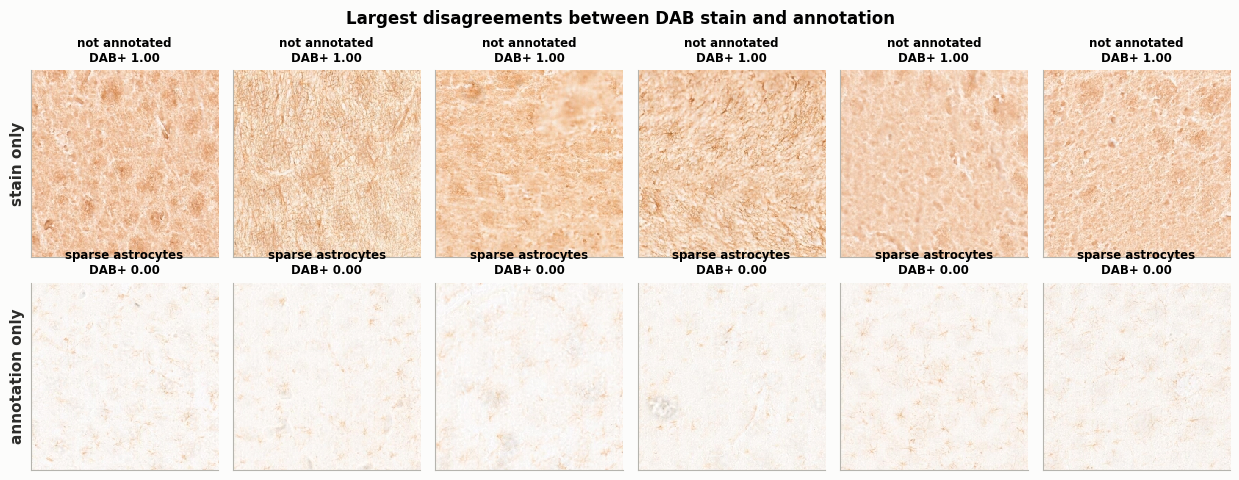

In [20]:
def spread_pick(candidates, n, min_tiles):
    # Greedy selection of the first n rows that are at least `min_tiles` apart on the grid.
    chosen = []
    for _, t in candidates.iterrows():
        if all(np.hypot(t.row - c.row, t.col - c.col) >= min_tiles for c in chosen):
            chosen.append(t)
        if len(chosen) == n:
            break
    return pd.DataFrame(chosen)


min_sep = int(np.ceil(2000 / TILE_UM))
stain_only = spread_pick(tiles[tiles.outcome == 3].sort_values("dab_pos_fraction", ascending=False), 6, min_sep)
annotation_only = spread_pick(tiles[tiles.outcome == 4].sort_values("dab_pos_fraction"), 6, min_sep)

fig, axes = plt.subplots(2, 6, figsize=(12.5, 4.9))
for r, (name, sel) in enumerate([("stain only", stain_only), ("annotation only", annotation_only)]):
    origins = [grid.to_level0(t.col, t.row) for _, t in sel.iterrows()]
    images = fetch_many(slide.path, origins, grid.downsample, 2)
    for c in range(6):
        ax = axes[r, c]
        ax.set_xticks([]); ax.set_yticks([])
        if c >= len(images):
            ax.axis("off")
            continue
        t = sel.iloc[c]
        ax.imshow(images[c])
        ax.set_title(f"{classes[int(t.grade)]}\nDAB+ {t.dab_pos_fraction:.2f}", fontsize=8.5)
    axes[r, 0].set_ylabel(name, fontsize=11, fontweight="bold")
plt.suptitle("Largest disagreements between DAB stain and annotation", fontweight="bold")
plt.tight_layout()
plt.show()

**Reading the gallery (default slide: GFAP, block 313, section 1583).**

*Stain only.* These tiles are not glass, folds or edge artefacts. They show genuinely DAB-positive tissue with a dense fibrillary texture and diffuse neuropil staining. The error map in Section 6.2 places them in one contiguous zone on the left of the section, around and partly inside the infarct outlined on the neighbouring H&E section. Two explanations fit these images. GFAP immunoreactivity may rise across a zone around the lesion that is wider than the area the annotator graded. Part of the brown signal in damaged tissue may also be non-specific chromogen deposition. Stain intensity alone cannot separate the two.

*Annotation only.* These tiles show individual astrocytes with thin processes on a pale background, graded *sparse*. They lie mostly on the right of the section, away from the lesion. The cells are recognisable by their shape, but they occupy too little of each tile to lift its DAB-positive fraction above τ.

Both error types have the same cause. The GFAP annotation grades astrocyte **state and density**, while the DAB measure counts **chromogen**. A single threshold cannot capture both, especially on a section where overall staining intensity changes with distance from the lesion.

*To explore:* switch the walkthrough to a HIF1a or FIB slide (Section 8 shows that these agree best) and compare the error map and the gallery.

## 8. Comparison across proteins

A single slide is one data point. This section repeats the tile-level analysis on `SLIDES_PER_PROTEIN` randomly drawn annotated slides for every protein in `COHORT_PROTEINS`, using exactly the same settings. Two threshold-free summaries are reported per slide:

* **AUC**: discrimination of annotated versus unannotated tiles by the DAB-positive fraction;
* **Spearman ρ**: rank correlation between the DAB-positive fraction and the annotation grade.

Candidate slides are first screened by total annotated area (`MIN_ANNOTATED_AREA_MM2`), which only requires the small annotation files. Slides whose image or annotation file is unavailable on the server are skipped and reported. Each slide takes 10–60 s to stream on a first run, depending on its size and the server load.

In [21]:
def annotated_area_mm2(url):
    # Total polygon area of one annotation file (NaN when the file is unavailable).
    try:
        return sum(a["geometry"].area for a in su.load_annotations(url)) * su.MPP_LEVEL0 ** 2 / 1e6
    except ValueError:
        return np.nan


def slide_metrics(row):
    t, *_ = quantify_slide(row, verbose=False)
    inc = t[t.included]
    y = inc.grade > 0
    enough = MIN_ANNOTATED_TILES <= y.sum() < len(y)
    auc = roc_auc_score(y, inc.dab_pos_fraction) if enough else np.nan
    rho = stats.spearmanr(inc.grade, inc.dab_pos_fraction)[0] if enough else np.nan
    return {"protein": row.protein, "biosample": row.biosample, "section": row.section,
            "tiles": len(inc), "annotated_tiles": int(y.sum()), "auc": auc, "spearman_rho": rho}


cohort_rng = np.random.default_rng(RANDOM_SEED)
records, skipped = [], []
for protein in COHORT_PROTEINS:
    candidates = su.find_slides(catalog, protein=protein, stain="IHC", annotated=True)
    with ThreadPoolExecutor(max_workers=8) as ex:
        candidates["annotated_mm2"] = list(ex.map(annotated_area_mm2, candidates.annotation_url))
    candidates = candidates[candidates.annotated_mm2 >= MIN_ANNOTATED_AREA_MM2]
    done = 0
    for i in cohort_rng.permutation(len(candidates)):
        if done == SLIDES_PER_PROTEIN:
            break
        row = candidates.iloc[i]
        try:
            records.append(slide_metrics(row))
            done += 1
            r = records[-1]
            print(f"{protein:>6}  block {row.biosample}  section {row.section:>5}   "
                  f"tiles {r['tiles']:>6}   annotated {r['annotated_tiles']:>5}   AUC {r['auc']:.2f}   "
                  f"rho {r['spearman_rho']:.2f}")
        except (ValueError, RuntimeError) as err:
            skipped.append((protein, row.biosample, row.section, str(err).splitlines()[0]))

cohort = pd.DataFrame(records)
if skipped:
    print("\nSkipped:", *[f"  {s}" for s in skipped], sep="\n")
cohort

 HIF1a  block 218  section   476   tiles  10476   annotated  4684   AUC 0.92   rho 0.76
 HIF1a  block 314  section   539   tiles  25694   annotated  1284   AUC 0.92   rho 0.32
 HIF1a  block 314  section   941   tiles  16779   annotated  3162   AUC 0.90   rho 0.55
   FIB  block 314  section   701   tiles  22711   annotated  1753   AUC 0.88   rho 0.35
   FIB  block 313  section   671   tiles  36052   annotated   257   AUC 0.69   rho 0.07
   FIB  block 314  section   623   tiles  24295   annotated  7195   AUC 0.98   rho 0.75
  CD68  block 217  section   227   tiles  35599   annotated  5958   AUC 0.84   rho 0.45
  CD68  block 218  section   524   tiles  12791   annotated  1005   AUC 0.68   rho 0.19
  CD68  block 313  section  1145   tiles  36706   annotated 12821   AUC 0.76   rho 0.45
  GFAP  block 313  section   167   tiles  11829   annotated  4155   AUC 0.53   rho 0.08
  GFAP  block 218  section  1397   tiles  28993   annotated  8342   AUC 0.81   rho 0.51
  GFAP  block 218  section   809

,protein,biosample,section,tiles,annotated_tiles,auc,spearman_rho
0,HIF1a,218,476,10476,4684,0.921,0.764
1,HIF1a,314,539,25694,1284,0.919,0.317
2,HIF1a,314,941,16779,3162,0.896,0.546
3,FIB,314,701,22711,1753,0.878,0.350
4,FIB,313,671,36052,257,0.692,0.070
5,FIB,314,623,24295,7195,0.975,0.752
6,CD68,217,227,35599,5958,0.836,0.446
7,CD68,218,524,12791,1005,0.681,0.188
8,CD68,313,1145,36706,12821,0.758,0.450
9,GFAP,313,167,11829,4155,0.532,0.077


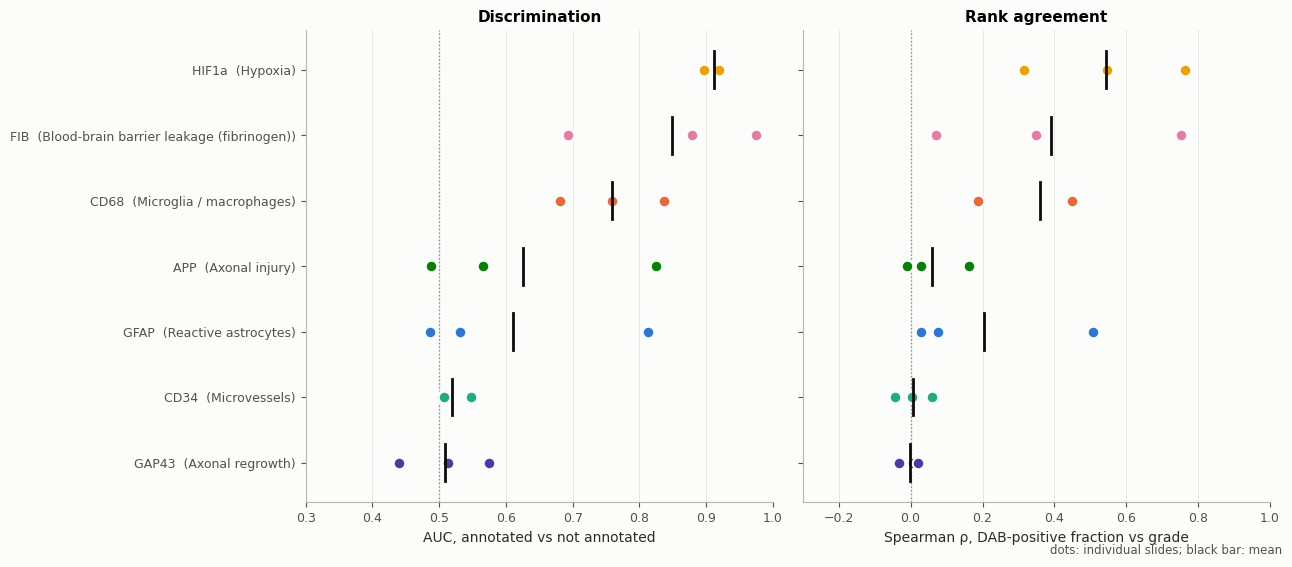

In [22]:
order = cohort.groupby("protein").auc.mean().sort_values().index.tolist()
fig, axes = plt.subplots(1, 2, figsize=(13, 0.55 * len(order) + 1.8), sharey=True)
for ax, column, label, ref in [(axes[0], "auc", "AUC, annotated vs not annotated", 0.5),
                               (axes[1], "spearman_rho", "Spearman ρ, DAB-positive fraction vs grade", 0.0)]:
    ax.axvline(ref, color="#8a8984", lw=1, ls=":")
    for y, protein in enumerate(order):
        values = cohort.loc[cohort.protein == protein, column].dropna()
        color = su.PROTEIN_COLORS.get(protein, "#52514e")
        ax.scatter(values, np.full(len(values), y), s=70, color=color, edgecolor="white", lw=1.5, zorder=3)
        if len(values):
            ax.plot([values.mean()] * 2, [y - 0.28, y + 0.28], color="#0b0b0b", lw=2, zorder=4)
    ax.set_xlabel(label)
    ax.grid(axis="x")
axes[0].set_yticks(range(len(order)), [f"{p}  ({su.PROTEIN_INFO[p]['marker']})" for p in order])
axes[0].set_xlim(0.3, 1.0)
axes[1].set_xlim(-0.3, 1.0)
axes[0].set_title("Discrimination")
axes[1].set_title("Rank agreement")
fig.text(0.99, 0.01, "dots: individual slides; black bar: mean", ha="right", fontsize=8.5, color="#52514e")
plt.tight_layout()
plt.show()

**Reading the comparison.** In the reference run (`SLIDES_PER_PROTEIN = 3`, `RANDOM_SEED = 7`) the proteins fall into three groups:

| Group | Proteins | AUC range | What the annotation captures |
|---|---|---|---|
| Stain intensity reproduces the annotation | HIF1a, FIB | 0.69–0.98 | Area-wide immunoreactivity: hypoxic cells and fibrinogen that has leaked into the parenchyma. Where the stain is, the annotation is. |
| Partial, slide-dependent agreement | CD68, GFAP, APP | 0.49–0.84 | Cell populations judged by density and morphology. DAB tracks the annotation on some slides and not on others. |
| No agreement | CD34, GAP43 | 0.44–0.57 | CD34 grades *microvessel density*, a count of thin structures that exist in all tissue. GAP43 marks small foci of axonal regrowth. Neither is a question of how much chromogen is present. |

Two practical consequences follow.

1. For HIF1a and fibrinogen, a calibrated DAB threshold is a fast, reasonable surrogate for the expert annotation. For example, it could screen the IHC slides in the catalogue that have no annotation file.
2. For the other proteins, reproducing the annotation requires a model of cell morphology and tissue context. The companion notebook `virtual_ihc_from_nissl_and_he.ipynb` goes a step further and asks whether such a model can predict the annotation from Nissl or H&E sections alone, without the IHC stain.

The spread between slides of the same protein is large, so treat the ordering as indicative. Increase `SLIDES_PER_PROTEIN` for tighter estimates; each additional slide costs 10–60 s on a first run.

## 9. Summary and limitations

### Findings
* On the walkthrough GFAP slide, the DAB-positive fraction separates annotated from unannotated tissue well (AUC about 0.8) and rises monotonically with grade, but barely separates the annotated grades from each other (AUC about 0.65 for the higher grades versus *sparse*).
* The disagreements are spatially organised. Strongly stained but unannotated tissue lies around the infarct, and faint but annotated sparse astrocytes lie away from it.
* Across proteins, stain intensity reproduces the annotation for diffuse markers (HIF1a, fibrinogen), partially for cellular markers (CD68, GFAP, APP), and not at all for CD34 microvessel density or GAP43.

### Limitations
* **Annotations are not exhaustive.** Unannotated tissue is treated as negative, which penalises the stain measure wherever an annotator chose not to mark mild changes.
* **Fixed stain vectors and threshold.** Colour deconvolution uses one set of reference vectors, and `DAB_THRESHOLD` is the same for every slide. AUC and ρ are computed per slide, so they are robust to a uniform shift in staining intensity, but not to intensity gradients within a slide.
* **Tile scale.** 256 µm tiles at about 4 µm per pixel suit region-level grades. Small or thin annotated structures, such as APP and GAP43 foci, are diluted at this scale.
* **Pixel size.** Physical units assume about 0.5 µm per full-resolution pixel. This value is estimated from section dimensions and nuclear size, because the scanner calibration is not published.
* **Sample size.** Section 8 analyses three slides per protein by default. The grouping is indicative and should be confirmed on more slides.

### Things to try
* Set `PROTEIN`, `BIOSAMPLE` and `SECTION` to a HIF1a or FIB slide and compare the error map with the GFAP example.
* Use `TILE_UM = 128` and `DOWNSAMPLE = 4` to compare at a finer scale (slower).
* Vary `DAB_THRESHOLD` and watch how the per-grade distributions, the ROC curves and the threshold sweep respond.
* Replace `dab_features` with a measure of your own, such as the number of DAB-positive objects per tile, and test whether it separates the grades better.

### Reference
Ruifrok, A. C. and Johnston, D. A. (2001). Quantification of histochemical staining by color deconvolution. *Analytical and Quantitative Cytology and Histology*, 23(4), 291–299.